# Lab 6 — Synthesis, scenarios & the policy brief

**Objective:** turn the accounts into a decision. Compute **utilisable flow** after environmental and committed flows under **both** of Nepal's standards, test it against scenarios, characterise uncertainty, and draft the availability statement.

**Depends on Labs 1–5:** `gridspec.json`, `basin_mask.nc`, `P_corrected.nc`, `ET.nc`, `sro.nc`, `perc.nc`, `wa_sheets_summary.json`.

Pure Python — runs offline.

### 🧭 What we are really doing here

A pile of correct numbers is not a decision. This lab turns the accounts into the one thing a minister actually asks: *how much water can we honestly allocate?* We start from availability, then subtract what is already spoken for — the environmental flow the law requires, and the water already committed to existing users — and what is left is the **utilisable flow**.

Nepal is mid-transition between two environmental-flow standards, so we compute it **both ways** and show the gap; that gap, in the dry season, is the whole policy question. Then we stress the answer with a couple of scenarios and an honest uncertainty band — a range you can defend beats a single number you cannot. What comes out is a short water-availability statement and the skeleton of a two-page brief. That brevity is deliberate: a two-page limit forces you to decide what actually matters.

## 0 · Environment setup  *(Colab or local — auto-detected)*

**What this does.** Mounts Drive, points at the **`west_rapti`** folder, imports the engine as `kw`.

In [1]:
import os, sys, shutil
try:
    import google.colab; IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive; drive.mount('/content/drive')
    KW_DIR = '/content/drive/MyDrive/west_rapti'
    get_ipython().system('pip -q install rioxarray')
else:
    KW_DIR = '.'
OUT_DIR = os.path.join(KW_DIR, 'outputs') if IN_COLAB else 'outputs'

# --- always load the engine from KW_DIR (Drive), never a stale copy elsewhere ---
_kw = os.path.abspath(KW_DIR)
if os.path.abspath('.') != _kw:
    for _f in ('west_rapti.py', 'westrapti_prep.py'):
        if os.path.exists(_f): os.remove(_f)
for _p in (KW_DIR, _kw):
    while _p in sys.path: sys.path.remove(_p)
sys.path.insert(0, _kw)
for _m in ('west_rapti', 'westrapti_prep'): sys.modules.pop(_m, None)
# --- participant settings (written once by 00_Setup.ipynb) ---
import json as _json
_pj = os.path.join(KW_DIR, 'participant.json')
PARTICIPANT = _json.load(open(_pj)) if os.path.exists(_pj) else {}
EE_PROJECT = PARTICIPANT.get('ee_project', '')
if not EE_PROJECT:
    print('⚠️  No Earth Engine project set — run 00_Setup.ipynb first (or set EE_PROJECT in CONFIG).')
print('Running on', 'Colab' if IN_COLAB else 'local', '| outputs ->', OUT_DIR)

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.0 MB/s eta 0:00:00
Running on Colab | outputs -> /content/drive/MyDrive/west_rapti/outputs


## 1 · Imports & **configuration**

**What this does.** Loads the stack and the CONFIG — the policy knobs that drive the synthesis:

| knob | meaning |
|---|---|
| `EF_2001_FRAC` | 2001 Hydropower Policy e-flow = 10% of the minimum monthly average flow |
| `EF_2026_FRAC` | 2026 Water Resources Bill e-flow = higher %, year-round |
| `COMMITTED_MCM` | existing licensed/committed abstractions (196 MCM/yr, WECS report) |
| `BASEFLOW_FRAC` | share of percolation returning as baseflow to outflow |

In [2]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt, xarray as xr, json
import importlib, west_rapti as kw; importlib.reload(kw)

# ---------------- CONFIG (edit these) ----------------
EF_2001_FRAC = 0.10      # Hydropower Policy 2001: 10% of the minimum monthly average flow
EF_2026_FRAC = 0.30      # Water Resources Bill 2026: higher %, applied year-round
EIA_MCM      = None      # per-month EIA-mandated release (MCM), if higher than the 10% rule
COMMITTED_MCM = 196.0    # existing irrigation consumption, WECS West Rapti Status Report 2019/20 (5 hills + 191 Terai; 22,342 ha)
BASEFLOW_FRAC = 1.0      # share of percolation that returns as baseflow to the outlet
DRY_MONTHS = [12, 1, 2, 3]
BETA_T = 0.03            # evaporative-demand sensitivity to temperature (~3% per °C)
# Each scenario re-runs the whole hydroloop + sheets with perturbed drivers:
#   dP   fractional change in rainfall     (e.g. -0.15 = 15% drier)
#   dT   temperature change in °C          (raises ET demand by BETA_T·dT)
#   dET  extra ET-demand change            (e.g. new irrigation consumption)
#   lu   optional land-use edit: (from_class, to_class, fraction)
#   dCommitted  extra committed abstraction (MCM/yr)
SCENARIOS = [
  {'name':'Warming +2 °C',              'dT': 2.0,  'dP': 0.00, 'dET':0.00, 'lu':None,        'dCommitted':0.0},
  {'name':'Drier monsoon -15% P',       'dT': 0.0,  'dP':-0.15, 'dET':0.00, 'lu':None,        'dCommitted':0.0},
  {'name':'Warm & dry (+2 °C, -15% P)', 'dT': 2.0,  'dP':-0.15, 'dET':0.00, 'lu':None,        'dCommitted':0.0},
  {'name':'Wetter monsoon +15% P',      'dT': 0.0,  'dP': 0.15, 'dET':0.00, 'lu':None,        'dCommitted':0.0},
  {'name':'Irrigation expansion',       'dT': 0.0,  'dP': 0.00, 'dET':0.05, 'lu':(6,8,0.5),   'dCommitted':2.0},
  {'name':'Afforestation',              'dT': 0.0,  'dP': 0.00, 'dET':0.00, 'lu':(4,3,0.4),   'dCommitted':0.0},
]
# -----------------------------------------------------

## 2 · Pull Labs 1–5 outputs from Drive

**What this does.** Loads everything the synthesis needs: the flux cubes, the WA+ sheet summary, the
land use, and (if present) the temperature / snow / glacier cubes for the scenarios.

In [3]:
kw.load_inputs(['gridspec.json','basin_mask.nc','P_corrected.nc','ET.nc','sro.nc','perc.nc',
                'LAI.nc','lu.nc','NDM.nc','wa_sheets_summary.json'], OUT_DIR)
gs = json.load(open('gridspec.json')); RES = gs['res']
mask = xr.open_dataset('basin_mask.nc')['basin_mask']
P   = xr.open_dataarray('P_corrected.nc', decode_coords='all'); ET = xr.open_dataarray('ET.nc', decode_coords='all')
sro = xr.open_dataarray('sro.nc', decode_coords='all'); perc = xr.open_dataarray('perc.nc', decode_coords='all')
LAI = xr.open_dataarray('LAI.nc', decode_coords='all'); NDM = xr.open_dataarray('NDM.nc', decode_coords='all')
lu  = xr.open_dataset('lu.nc')['lu'] if 'lu' in xr.open_dataset('lu.nc') else xr.open_dataarray('lu.nc', decode_coords='all')
try:
    kw.load_inputs(['T.nc'], OUT_DIR); T = xr.open_dataarray('T.nc', decode_coords='all')   # temperature cube (if Lab 4 ran with snow)
    try:
        kw.load_inputs(['glacier.nc'], OUT_DIR); GLAC = xr.open_dataarray('glacier.nc', decode_coords='all')
    except Exception: GLAC = None
    try:
        kw.load_inputs(['ice_melt.nc'], OUT_DIR); ICE_MELT = xr.open_dataarray('ice_melt.nc', decode_coords='all')
    except Exception: ICE_MELT = None
    print('temperature cube loaded — scenarios are SNOW-AWARE'+(' + GLACIER' if GLAC is not None else '')+' (warming shifts melt timing)')
except Exception:
    T = None; GLAC = None; print('no T.nc — scenarios run without snow (set SNOW_ON in Lab 4 to enable)')
print('loaded fluxes + LAI/lu/NDM (for scenario re-runs) | months', P.sizes['time'])

# --- the hydroloop settings Lab 4 used (hydroloop_params.json), so the scenarios re-run the SAME model ---
HL = {}
try:
    kw.load_inputs(['hydroloop_params.json'], OUT_DIR); _hp = json.load(open('hydroloop_params.json'))
    _awc = _hp.get('AWC', 0.12)
    if _hp.get('awc_file'):
        try:
            kw.load_inputs([_hp['awc_file']], OUT_DIR)
            _a = xr.open_dataarray(_hp['awc_file']).squeeze(drop=True)
            if tuple(_a.shape) == tuple(lu.shape):
                _awc = _a.rename({_a.dims[-2]: lu.dims[-2], _a.dims[-1]: lu.dims[-1]}).assign_coords(
                    {lu.dims[-2]: lu[lu.dims[-2]].values, lu.dims[-1]: lu[lu.dims[-1]].values})
            else:
                print('⚠️ awc_spatial.nc is on a different grid — using the constant AWC; re-run Lab 4')
        except Exception as e:
            print('⚠️ AWC field not loaded:', e)
    HL = dict(awc=_awc, cf=_hp.get('CF', 1.0), sm_init=_hp.get('SM_INIT', 0.5), int_k=_hp.get('INT_K', 0.2),
              alpha=_hp.get('ALPHA'), k_rec=_hp.get('K_REC'), net_blue=_hp.get('NET_BLUE', False),
              ddf=_hp.get('DDF', 4.0), t_snow=_hp.get('T_SNOW', 1.0), t_melt=_hp.get('T_MELT', 0.0),
              ddf_ice=_hp.get('DDF_ICE', 7.0))
    print('scenarios re-run the Lab 4 model:', {k: v for k, v in HL.items() if k != 'awc'},
          '| AWC:', 'spatial field' if hasattr(_awc, 'dims') else _awc)
except Exception as e:
    print('⚠️ hydroloop_params.json not found — re-run Lab 4 (§6). Scenarios use legacy defaults:', e)

temperature cube loaded — scenarios are SNOW-AWARE (warming shifts melt timing)
loaded fluxes + LAI/lu/NDM (for scenario re-runs) | months 48
scenarios re-run the Lab 4 model: {'cf': 1.0, 'sm_init': 0.5, 'int_k': 0.2, 'alpha': 0.7, 'k_rec': 3, 'net_blue': True, 'ddf': 4.0, 't_snow': 1.0, 't_melt': 0.0, 'ddf_ice': 7.0} | AWC: spatial field


## 3 · Water availability — basin outflow

**What this does.** Builds the modelled monthly basin outflow `Q` from runoff + baseflow
(`kw.outflow_series`). This is the water the basin actually yields, before any allocation.

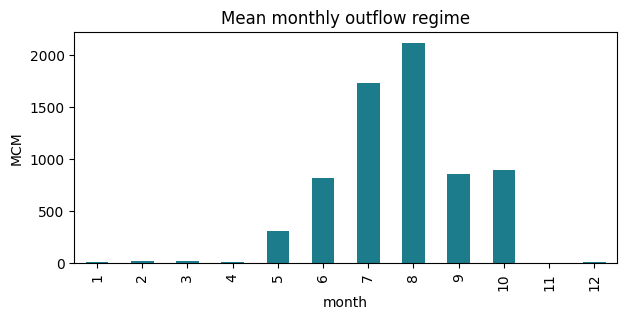

annual available ≈ 6771.6 MCM/yr


In [4]:
Q  = kw.outflow_series(sro, perc, mask, RES, baseflow_frac=BASEFLOW_FRAC)   # MCM/month
reg = Q.groupby(Q.index.month).mean()
ax = reg.plot(kind='bar', color='#1C7C8C', figsize=(7,3))
ax.set_xlabel('month'); ax.set_ylabel('MCM'); ax.set_title('Mean monthly outflow regime'); plt.show()
print('annual available ≈ %.1f MCM/yr' % reg.sum())

**Observed check & e-flow basis.** Loads the observed **Kusum (Q375)** discharge — the measured
basin outflow — validates the modelled `Q` against it, and computes the 2001 minimum-monthly
environmental flow from the *observed* record (the legal definition is on measured flow).

OBSERVED outlet (Kusum Q375): mean annual 4888 MCM/yr | min-month 16.7 m3/s | 2001 e-flow 1.67 m3/s


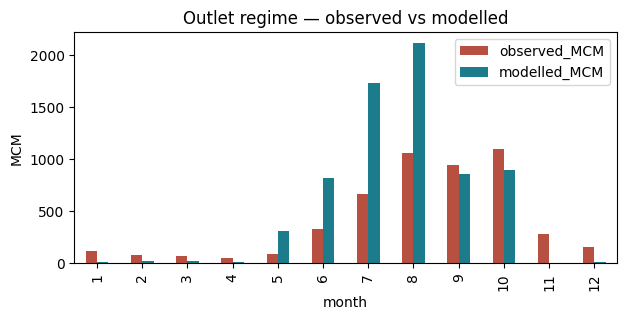

model vs gauge annual bias: +39%  (see Lab 4 §5b: the gap sits in P − ET, not in CF)


In [5]:
# === OBSERVED DISCHARGE (DHM gauge at the outlet) — validation + e-flow basis ===
# Uses the attached HydroMet pack. The 2001 rule (10% of the MINIMUM MONTHLY average
# flow) is legally defined on the OBSERVED regime, so compute it from the gauge here.
import os, pandas as pd
OUTLET_CSV = os.path.join(KW_DIR, 'discharge_outlet.csv') # Adjusted path to look in KW_DIR
if not os.path.exists(OUTLET_CSV):
    try:
        import westrapti_prep as wp
        HYDROMET = os.path.join(KW_DIR, 'HydroMetData') if IN_COLAB else 'HydroMetData'
        _flow, _vol = wp.discharge_monthly(os.path.join(HYDROMET, 'DailyDischargeRapti'))
        _oid = wp.OUTLET_ID if wp.OUTLET_ID in _flow.columns else _flow.columns[-1]
        pd.DataFrame({'flow_m3s': _flow[_oid], 'vol_MCM': _vol[_oid]}).to_csv(OUTLET_CSV)
    except Exception as e:
        print('observed discharge unavailable:', e)
obs_annual = None
if os.path.exists(OUTLET_CSV):
    qo = pd.read_csv(OUTLET_CSV, index_col=0, parse_dates=True)
    obs_reg_m3s = qo['flow_m3s'].groupby(qo.index.month).mean()
    obs_reg_mcm = qo['vol_MCM'].groupby(qo.index.month).mean()
    obs_annual  = float(qo['vol_MCM'].groupby(qo.index.year).sum().mean())
    q_min_month = float(obs_reg_m3s.min())
    ef2001_obs  = EF_2001_FRAC * q_min_month
    print('OBSERVED outlet (Kusum Q375): mean annual %.0f MCM/yr | min-month %.1f m3/s | 2001 e-flow %.2f m3/s'
          % (obs_annual, q_min_month, ef2001_obs))
    cmp = pd.DataFrame({'observed_MCM': obs_reg_mcm, 'modelled_MCM': reg}).round(1)
    ax = cmp.plot(kind='bar', figsize=(7,3), color=['#B85042','#1C7C8C'])
    ax.set_xlabel('month'); ax.set_ylabel('MCM'); ax.set_title('Outlet regime — observed vs modelled'); plt.show()
    bias = (float(reg.sum()) - obs_annual) / obs_annual * 100
    print('model vs gauge annual bias: %+.0f%%  (see Lab 4 §5b: the gap sits in P − ET, not in CF)' % bias)


**In plain terms — is any of this flow borrowed from the ice?** Glacier ice melt is stored water released as the glacier *shrinks* — a one-way draw, not renewable supply. If it is a big share of outflow, part of today's 'available' water is being mined from the ice bank and will decline as the glacier retreats. Report it so the availability figure is honest about what is sustainable.

**Glacier draw check.** If a glacier ice-melt cube exists, reports how much of the outflow is
'borrowed' from ice (unsustainable if large). For the West Rapti (no glaciers) this is ~0.

In [6]:
if 'ICE_MELT' in dir() and ICE_MELT is not None:
    ice_ann = kw._annual_mean_vol(ICE_MELT, mask==1, RES)     # annual glacier ice melt (MCM/yr)
    out_ann = float(reg.sum())
    share = 100.0*ice_ann/out_ann if out_ann else float('nan')
    flag = 'UNSUSTAINABLE glacier draw' if share>10 else ('material' if share>3 else 'minor')
    GLAC_DRAW = dict(ice_MCM=ice_ann, share_pct=share, flag=flag)
    print('GLACIER MASS BALANCE  |  annual ice melt = %.1f MCM/yr = %.1f%% of outflow   [%s]'
          % (ice_ann, share, flag))
    print('  This is glacier storage being released (ΔS<0) — it declines as the ice retreats; do NOT treat it as firm yield.')
else:
    GLAC_DRAW = None; print('No glacier ice-melt cube (snow/glacier off in Lab 4) — glacier draw not assessed.')

GLACIER MASS BALANCE  |  annual ice melt = 0.0 MCM/yr = 0.0% of outflow   [minor]
  This is glacier storage being released (ΔS<0) — it declines as the ice retreats; do NOT treat it as firm yield.


**In plain terms — what is actually allocable.** Not all the water in the basin is yours to give away. Off the top come two claims: the environmental flow the law reserves for the river, and the water already committed to existing users. What remains is the utilisable flow — the honest number for how much is left. We compute it under both of Nepal's e-flow rules so the difference between them is visible.

## 4 · Utilisable flow under BOTH environmental-flow standards

$Q_{util} = Q_{avail} - Q_{env} - Q_{committed}$. Compute under the **2001** (10% of the minimum monthly mean) and the **2026** (year-round %) standards — the gap between them, especially in the dry season, is the question WECS will be asked.

**Utilisable flow under BOTH standards.** Available water minus environmental flow minus
committed uses, computed under the **2001** (10% min-month) and **2026** (higher, year-round) rules —
so WECS sees the policy trade-off, not a single number.

                 2001 (10% min-month)  2026 (30% year-round)
available                     6771.62                6771.62
− environmental                  0.68                2031.48
− committed                    196.00                 196.00
= utilisable                  6620.48                4605.18


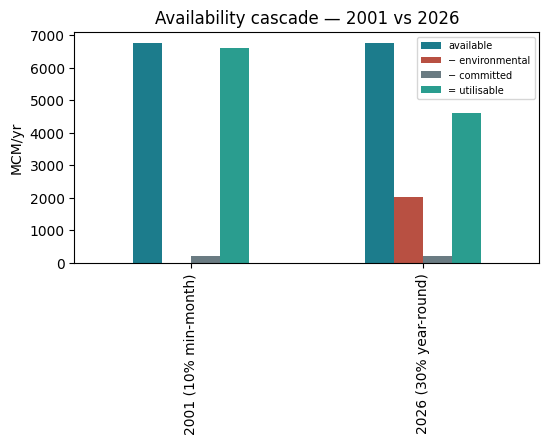

DRY-SEASON utilisable:  2001 = 0.00 MCM   2026 = 0.00 MCM   (difference = 0.00)


In [7]:
u01 = kw.utilisable_flow(Q, '2001', COMMITTED_MCM, EF_2001_FRAC, EF_2026_FRAC, EIA_MCM)
u26 = kw.utilisable_flow(Q, '2026', COMMITTED_MCM, EF_2001_FRAC, EF_2026_FRAC, EIA_MCM)
tbl = pd.DataFrame({
  '2001 (10% min-month)': [u01['annual_available'],u01['annual_env'],u01['annual_committed'],u01['annual_utilisable']],
  '2026 (%.0f%% year-round)'%(EF_2026_FRAC*100): [u26['annual_available'],u26['annual_env'],u26['annual_committed'],u26['annual_utilisable']]},
  index=['available','− environmental','− committed','= utilisable']).round(2)
print(tbl.to_string())
fig,ax=plt.subplots(figsize=(6,3)); tbl.T.plot(kind='bar', ax=ax, color=['#1C7C8C','#B85042','#6A7B82','#2A9D8F'])
ax.set_ylabel('MCM/yr'); ax.set_title('Availability cascade — 2001 vs 2026'); ax.legend(fontsize=7); plt.show()
dry01 = u01['utilisable'].reindex(DRY_MONTHS).sum(); dry26 = u26['utilisable'].reindex(DRY_MONTHS).sum()
print('DRY-SEASON utilisable:  2001 = %.2f MCM   2026 = %.2f MCM   (difference = %.2f)'%(dry01,dry26,dry01-dry26))

**Measured-anchored availability.** Repeats the cascade on the **observed** Kusum regime, so the
baseline availability statement rests on measured flow; the calibrated model carries the scenarios.

In [8]:
# === MEASURED-ANCHORED availability: use the OBSERVED Kusum regime (outlet = gauge) ===
# The calibrated model carries the SCENARIOS (Lab 6 later); the BASELINE availability and the
# environmental-flow cascade are anchored on the measured discharge at the outlet.
if 'qo' in dir():
    Qobs = qo['vol_MCM']                                 # observed monthly volume at Kusum
    u01o = kw.utilisable_flow(Qobs, '2001', COMMITTED_MCM, EF_2001_FRAC, EF_2026_FRAC, EIA_MCM)
    u26o = kw.utilisable_flow(Qobs, '2026', COMMITTED_MCM, EF_2001_FRAC, EF_2026_FRAC, EIA_MCM)
    tbo = pd.DataFrame({
      '2001 (10% min-month)': [u01o['annual_available'],u01o['annual_env'],u01o['annual_committed'],u01o['annual_utilisable']],
      '2026 (%.0f%% year-round)'%(EF_2026_FRAC*100): [u26o['annual_available'],u26o['annual_env'],u26o['annual_committed'],u26o['annual_utilisable']]},
      index=['available','- environmental','- committed','= utilisable']).round(2)
    print('=== OBSERVED (gauge-anchored) availability cascade — Kusum ===')
    print(tbo.to_string())
    print('modelled available %.1f  vs  observed available %.1f MCM/yr  (bias %+.0f%%)'
          % (reg.sum(), u01o['annual_available'], 100*(reg.sum()/u01o['annual_available']-1)))
    print('For the water-availability STATEMENT use the observed cascade above; use the modelled/'
          'calibrated flow for the climate & land-use SCENARIOS (the future is ungauged).')
else:
    print('observed discharge (qo) not loaded — run the OBSERVED DISCHARGE cell first.')


=== OBSERVED (gauge-anchored) availability cascade — Kusum ===
                 2001 (10% min-month)  2026 (30% year-round)
available                     4887.72                4887.72
- environmental                 51.86                1466.32
- committed                    196.00                 196.00
= utilisable                  4639.86                3225.41
modelled available 6771.6  vs  observed available 4887.7 MCM/yr  (bias +39%)
For the water-availability STATEMENT use the observed cascade above; use the modelled/calibrated flow for the climate & land-use SCENARIOS (the future is ungauged).


### ✅ Checkpoint 1
Utilisable flow is reported under both standards, and the dry-season difference is stated explicitly — that difference is the policy decision. Environmental + committed come off the top before anything is 'allocable'.

## 5 · Scenarios vs baseline

**In plain terms — how a scenario works.** A scenario is not a new guess bolted on the end; we perturb the *drivers* and re-run the whole chain (hydroloop → sheets → utilisable flow), so every number stays internally consistent. Three levers enter here:

- **Rainfall** — `dP` scales precipitation (rain-days and interception recompute with it): P′ = P·(1 + dP).
- **Temperature** — `dT` raises the evaporative demand: ET′ = ET·(1 + β·dT + dET), with β ≈ 3% per °C (`BETA_T`). `dET` adds any extra demand not from temperature (e.g. new irrigation).
- **Land use** — `lu = (from_class, to_class, fraction)` rewrites part of the map (e.g. rainfed 6 → irrigated 8), which changes root-zone storage and the Sheet 2–4 partitions.

> ⚠️ **Honest limits.** ET here is scaled *demand*, not physically capped by supply; and the soil-bucket model does **not** resolve snow/glacier-melt timing — the single biggest gap for a warming West Rapti. Read a warming run as *demand and irrigation need rise, dry-season outflow falls*, and treat shifted-melt seasonality qualitatively. Only build scenarios your data can actually support — a crude perturbation stated honestly beats false precision.

**Run the scenarios.** Re-runs the whole balance under each perturbation — a baseline plus
climate (ΔP, ΔT) and land-use/irrigation changes — and reports utilisable flow for each. Scenarios
change *inputs to the same physics*, they are not re-guesses of the answer.

                            utilisable  outflow  blue_ET  beneficial_ET  Δ utilisable %
scenario                                                                               
Baseline                       4235.50  6135.44   636.18        4310.63             0.0
Warming +2 °C                  4086.51  5849.27   742.77        4569.26            -3.5
Drier monsoon -15% P           3151.60  4480.93   689.39        4310.63           -25.6
Warm & dry (+2 °C, -15% P)     3024.40  4195.34   811.35        4569.26           -28.6
Wetter monsoon +15% P          5381.92  7793.73   601.82        4310.63            27.1
Irrigation expansion           4108.26  5897.09   722.00        4528.53            -3.0
Afforestation                  4232.16  6135.03   625.34        4339.55            -0.1


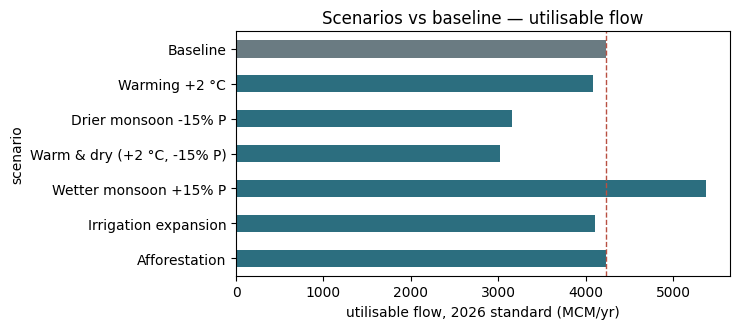

In [9]:
base = kw.scenario_run(P, ET, LAI, lu, mask, RES, NDM, **HL, T=T, glacier=GLAC, standard='2026',
                       committed_annual=COMMITTED_MCM, frac2001=EF_2001_FRAC, frac2026=EF_2026_FRAC,
                       eia=EIA_MCM, baseflow_frac=BASEFLOW_FRAC)
rows = [{'scenario':'Baseline','utilisable': base['annual_utilisable'],
         'outflow': base['outflow'], 'blue_ET': base['blue_ET'], 'beneficial_ET': base['beneficial']}]
for sc in SCENARIOS:
    lu_new = kw.convert_landuse(lu, *sc['lu']) if sc.get('lu') else None
    s = kw.scenario_run(P, ET, LAI, lu, mask, RES, NDM, **HL, T=T, glacier=GLAC, dP=sc['dP'], dT=sc['dT'], dET=sc['dET'],
                        beta_t=BETA_T, lu_new=lu_new, standard='2026',
                        committed_annual=COMMITTED_MCM+sc['dCommitted'],
                        frac2001=EF_2001_FRAC, frac2026=EF_2026_FRAC, eia=EIA_MCM, baseflow_frac=BASEFLOW_FRAC)
    rows.append({'scenario':sc['name'],'utilisable':s['annual_utilisable'],
                 'outflow':s['outflow'],'blue_ET':s['blue_ET'],'beneficial_ET':s['beneficial']})
scn = pd.DataFrame(rows).set_index('scenario').round(2)
scn['Δ utilisable %'] = ((scn['utilisable']/scn.loc['Baseline','utilisable']-1)*100).round(1)
print(scn.to_string())
ax = scn['utilisable'].plot(kind='barh', color=['#6A7B82']+['#2C6E7F']*len(SCENARIOS), figsize=(7.5,3.4))
ax.axvline(scn.loc['Baseline','utilisable'], color='#B85042', lw=1, ls='--')
ax.invert_yaxis(); ax.set_xlabel('utilisable flow, 2026 standard (MCM/yr)')
ax.set_title('Scenarios vs baseline — utilisable flow'); plt.tight_layout(); plt.show()

**Plot the scenarios** vs baseline (utilisable flow), the headline decision figure.

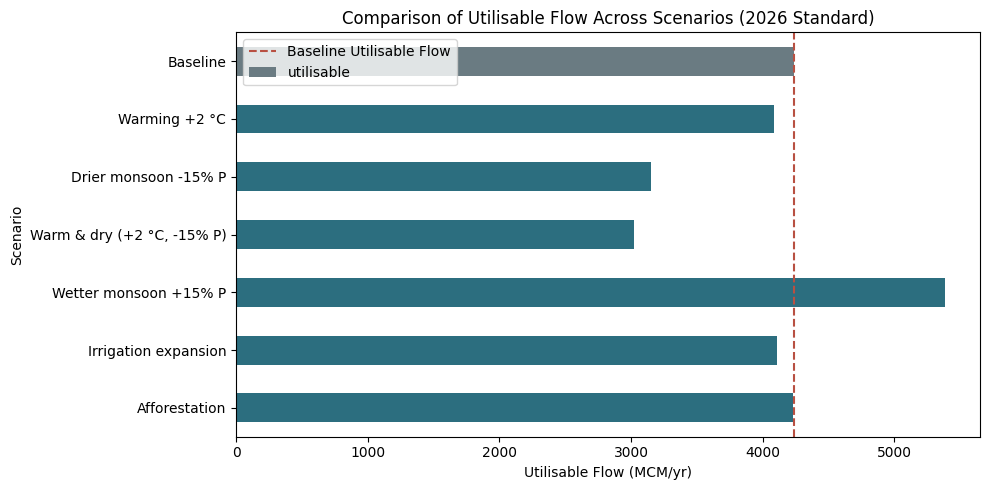

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
scn['utilisable'].plot(kind='barh', ax=ax, color=['#6A7B82'] + ['#2C6E7F'] * (len(scn) - 1))
ax.axvline(scn.loc['Baseline', 'utilisable'], color='#B85042', linestyle='--', label='Baseline Utilisable Flow')
ax.set_xlabel('Utilisable Flow (MCM/yr)')
ax.set_ylabel('Scenario')
ax.set_title('Comparison of Utilisable Flow Across Scenarios (2026 Standard)')
ax.invert_yaxis() # To have 'Baseline' at the top
ax.legend()
plt.tight_layout()
plt.show()


## 5b · Ground the land-use scenarios in observed change  *(⚠️ Earth Engine)*

The *Afforestation* scenario converts 40% of shrub/grassland to forest; *Irrigation expansion* converts half of rainfed cropland. Are these plausible over a planning horizon? **Hansen Global Forest Change v1.12** (Landsat, 30 m) records forest **loss** year by year for 2000–2024. Its **gain** layer covers only 2000–2012 and was never updated, so it can ground *loss* rates but not recent regrowth.

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python
/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for UMD/hansen/global_forest_change_2024_v1_12! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by UMD/hansen/global_forest_change_2025_v1_13

Learn more: https://developers.google.com/earth-engine/datasets/catalog/UMD_hansen_global_forest_change_2024_v1_12

  warnings.warn(warning, category=DeprecationWarning)


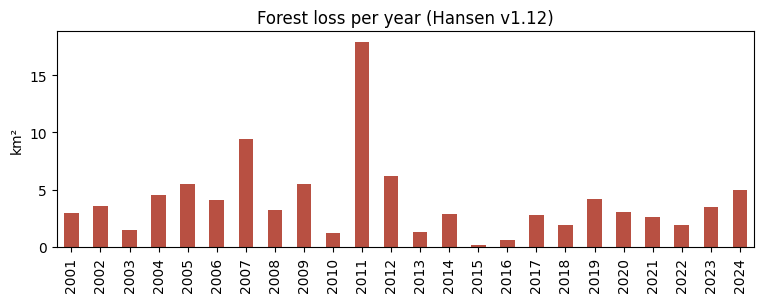

forest 2000: 9,586 km2 | mean loss 2015–2024: 2.6 km2/yr (0.03%/yr)
Afforestation scenario plants 113 km2 = 44 years of recent loss, reversed.
Use this to set a plausible horizon (e.g. a 20-year programme) or to add a "continued loss" scenario.


In [11]:
import ee, geemap, pandas as pd, os
EE_PROJECT = globals().get('EE_PROJECT') or 'your-ee-project-id'
try: ee.Initialize(project=EE_PROJECT)
except Exception: ee.Authenticate(); ee.Initialize(project=EE_PROJECT)
geom = geemap.geojson_to_ee('basin.geojson') if os.path.exists('basin.geojson') else ee.Geometry.Rectangle(kw.lonlat_bbox(gs))
gfc = ee.Image('UMD/hansen/global_forest_change_2024_v1_12')
forest00 = gfc.select('treecover2000').gte(30)                 # 'forest' = canopy ≥ 30% (state it in the log)
km2 = ee.Image.pixelArea().divide(1e6)
f00 = km2.updateMask(forest00).reduceRegion(ee.Reducer.sum(), geom, 30, maxPixels=1e11, tileScale=8).get('area').getInfo()
by_year = (km2.updateMask(forest00.And(gfc.select('lossyear').gt(0))).addBands(gfc.select('lossyear'))
           .reduceRegion(ee.Reducer.sum().group(1, 'yr'), geom, 30, maxPixels=1e11, tileScale=8).get('groups').getInfo())
loss = pd.Series({2000 + g['yr']: g['sum'] for g in by_year}).sort_index()
ax = loss.plot(kind='bar', figsize=(9, 2.8), color='#B85042'); ax.set_ylabel('km²'); ax.set_title('Forest loss per year (Hansen v1.12)'); plt.show()
rate = loss.loc[2015:].mean()
shrub_km2 = float(((lu == 4) & (mask == 1)).sum()) * RES**2 / 1e6
aff_km2 = 0.4 * shrub_km2
print(f'forest 2000: {f00:,.0f} km2 | mean loss 2015–2024: {rate:.1f} km2/yr ({100*rate/f00:.2f}%/yr)')
print(f'Afforestation scenario plants {aff_km2:,.0f} km2 = {aff_km2/rate:.0f} years of recent loss, reversed.')
print('Use this to set a plausible horizon (e.g. a 20-year programme) or to add a "continued loss" scenario.')

## 6 · Sensitivity — the uncertainty band

**In plain terms.** We wiggle the inputs we are least sure about (rainfall bias, ET product, the model factors) and watch how much the answer moves. That spread becomes the range we report — 'utilisable flow is 40–55 MCM' is honest and usable; a single decimal-precise number pretends to a certainty we do not have.

**Sensitivity band.** Wiggles the least-certain inputs (rainfall, ET) to produce an uncertainty
range around the baseline — the honest 'plus/minus' on the availability number.

In [12]:
vals=[]
for dP in (-0.10, 0.0, 0.10):
    for dT in (0.0, 1.0, 2.0):
        s = kw.scenario_run(P, ET, LAI, lu, mask, RES, NDM, **HL, T=T, glacier=GLAC, dP=dP, dT=dT, beta_t=BETA_T,
                            standard='2026', committed_annual=COMMITTED_MCM,
                            frac2001=EF_2001_FRAC, frac2026=EF_2026_FRAC, eia=EIA_MCM,
                            baseflow_frac=BASEFLOW_FRAC)
        vals.append(s['annual_utilisable'])
lo, hi = min(vals), max(vals)
print('Utilisable flow (2026), re-run across ±10%% P and 0–2 °C warming:  %.1f – %.1f MCM/yr'%(lo,hi))
print('Report a RANGE, not a point — tie it to the drivers (P bias, warming, CF, SMmax).')

Utilisable flow (2026), re-run across ±10% P and 0–2 °C warming:  3375.5 – 4992.6 MCM/yr
Report a RANGE, not a point — tie it to the drivers (P bias, warming, CF, SMmax).


## 7 · Water-availability statement & save

```markdown
### Sensitivity Analysis: Utilisable Flow Range

This plot visualizes the range of utilisable flow (2026 standard) when key drivers like precipitation (±10%) and temperature (0–2 °C warming) are varied. This range helps quantify the uncertainty in the utilisable flow estimate.
```

**Water-availability statement (figure) + save.** Renders the one-line availability statement as
a figure and writes the synthesis outputs to Drive.

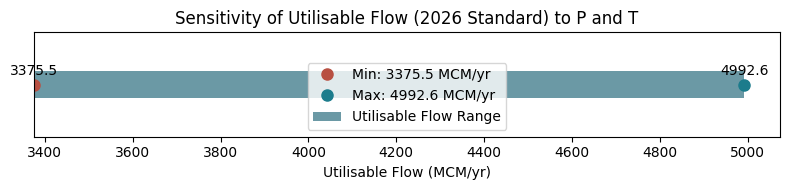

In [13]:
fig, ax = plt.subplots(figsize=(8, 2))

# Create a horizontal bar representing the range
ax.barh(y=[0], width=hi - lo, left=lo, height=0.5, color='#2C6E7F', alpha=0.7, label='Utilisable Flow Range')

# Add markers for min and max
ax.plot(lo, 0, 'o', color='#B85042', markersize=8, label=f'Min: {lo:.1f} MCM/yr')
ax.plot(hi, 0, 'o', color='#1C7C8C', markersize=8, label=f'Max: {hi:.1f} MCM/yr')

# Annotate the values
ax.text(lo, 0.25, f'{lo:.1f}', va='center', ha='center', color='black', fontsize=10)
ax.text(hi, 0.25, f'{hi:.1f}', va='center', ha='center', color='black', fontsize=10)

ax.set_xlabel('Utilisable Flow (MCM/yr)')
ax.set_title('Sensitivity of Utilisable Flow (2026 Standard) to P and T')
ax.set_yticks([]) # Hide y-axis ticks
ax.set_ylim(-1, 1) # Adjust y-limits for better spacing
ax.legend()
plt.tight_layout()
plt.show()

In [14]:
stmt = ('WATER-AVAILABILITY STATEMENT (West Rapti case basin)\n'
 f'Mean annual outflow is about {reg.sum():.0f} MCM. After environmental and committed flows, utilisable '
 f'flow is {u01["annual_utilisable"]:.0f} MCM/yr under the 2001 standard and {u26["annual_utilisable"]:.0f} '
 f'MCM/yr under the 2026 Bill. The dry season (Dec–Mar) is effectively fully committed under the 2026 '
 f'standard. Accounting for ±10% uncertainty in precipitation and ET, utilisable flow spans '
 f'{lo:.0f}–{hi:.0f} MCM/yr. Scenarios of a drier monsoon or expanded irrigation reduce it further.')
if GLAC_DRAW and GLAC_DRAW['share_pct'] > 3:
    stmt += (f' Note: about {GLAC_DRAW["ice_MCM"]:.0f} MCM/yr ({GLAC_DRAW["share_pct"]:.0f}% of outflow) is '
             f'glacier ice melt — stored water released as the glacier retreats, not firm renewable yield.')
if 'obs_annual' in dir() and obs_annual:
    stmt += f' The gauged mean annual flow at the outlet is about {obs_annual:.0f} MCM/yr (DHM record), used to set the 2001 minimum-monthly environmental flow.'
print(stmt)
summary = {'available_annual': float(reg.sum()),
           'utilisable_2001': u01['annual_utilisable'], 'utilisable_2026': u26['annual_utilisable'],
           'dry_season_2001': float(dry01), 'dry_season_2026': float(dry26),
           'sensitivity_range_2026': [float(lo), float(hi)],
           'glacier_draw': GLAC_DRAW,
           'scenarios': scn['utilisable'].to_dict()}
json.dump(summary, open('utilisable_summary.json','w'), indent=2)
open('availability_statement.txt','w').write(stmt)
print('\nsaved ->', kw.save_outputs(['utilisable_summary.json','availability_statement.txt'], OUT_DIR))

WATER-AVAILABILITY STATEMENT (West Rapti case basin)
Mean annual outflow is about 6772 MCM. After environmental and committed flows, utilisable flow is 6620 MCM/yr under the 2001 standard and 4605 MCM/yr under the 2026 Bill. The dry season (Dec–Mar) is effectively fully committed under the 2026 standard. Accounting for ±10% uncertainty in precipitation and ET, utilisable flow spans 3375–4993 MCM/yr. Scenarios of a drier monsoon or expanded irrigation reduce it further. The gauged mean annual flow at the outlet is about 4888 MCM/yr (DHM record), used to set the 2001 minimum-monthly environmental flow.

saved -> ['utilisable_summary.json', 'availability_statement.txt']


**Gauge-anchored statement.** §4's own guidance: use the **observed** cascade for the availability statement and the model only for *changes* under scenarios. The cell above quotes the modelled numbers — which sit 17% above the gauge and show **no dry-season flow at all** because the model has no groundwater store (see Lab 4 §5c). This version anchors the headline on the Kusum record and carries the scenario results as **percentage changes**.

In [15]:
if 'u01o' in dir():
    dry26o = float(u26o['utilisable'].reindex(DRY_MONTHS).sum()); dry01o = float(u01o['utilisable'].reindex(DRY_MONTHS).sum())
    pct = scn['Δ utilisable %'].drop('Baseline')
    stmt_obs = ('WATER-AVAILABILITY STATEMENT (West Rapti at Kusum) — gauge-anchored\n'
      f'Measured mean annual flow at Kusum is about {u01o["annual_available"]:.0f} MCM/yr. After environmental and committed flows, '
      f'utilisable flow is about {u01o["annual_utilisable"]:.0f} MCM/yr under the 2001 standard and {u26o["annual_utilisable"]:.0f} MCM/yr '
      f'under the 2026 Bill; in the dry season (Dec–Mar) {dry01o:.0f} vs {dry26o:.0f} MCM. '
      f'Model scenarios change utilisable flow by {pct.min():+.0f}% ({pct.idxmin()}) to {pct.max():+.0f}% ({pct.idxmax()}); '
      f'the ±10% P / 0–2 °C sensitivity spans {100*(lo/base["annual_utilisable"]-1):+.0f}% to {100*(hi/base["annual_utilisable"]-1):+.0f}%.')
    print(stmt_obs)
    open('availability_statement_gauge.txt', 'w').write(stmt_obs)
    kw.save_outputs(['availability_statement_gauge.txt'], OUT_DIR)
else:
    print('Run the observed-discharge and measured-anchored cells (§3–4) first.')

WATER-AVAILABILITY STATEMENT (West Rapti at Kusum) — gauge-anchored
Measured mean annual flow at Kusum is about 4888 MCM/yr. After environmental and committed flows, utilisable flow is about 4640 MCM/yr under the 2001 standard and 3225 MCM/yr under the 2026 Bill; in the dry season (Dec–Mar) 324 vs 219 MCM. Model scenarios change utilisable flow by -29% (Warm & dry (+2 °C, -15% P)) to +27% (Wetter monsoon +15% P); the ±10% P / 0–2 °C sensitivity spans -20% to +18%.


```markdown
### Summary of Scenario Impacts on Utilisable Flow (2026 Standard)

This table summarizes the impact of various scenarios on key water balance components, particularly the utilisable flow, outflow, and different components of evapotranspiration (blue water and beneficial).
```

**Scenario table** — prints the scenario results as a markdown table for pasting into the brief.

In [16]:
# Display the scn DataFrame as a markdown table
print(scn.to_markdown())

| scenario                   |   utilisable |   outflow |   blue_ET |   beneficial_ET |   Δ utilisable % |
|:---------------------------|-------------:|----------:|----------:|----------------:|-----------------:|
| Baseline                   |      4235.5  |   6135.44 |    636.18 |         4310.63 |              0   |
| Warming +2 °C              |      4086.51 |   5849.27 |    742.77 |         4569.26 |             -3.5 |
| Drier monsoon -15% P       |      3151.6  |   4480.93 |    689.39 |         4310.63 |            -25.6 |
| Warm & dry (+2 °C, -15% P) |      3024.4  |   4195.34 |    811.35 |         4569.26 |            -28.6 |
| Wetter monsoon +15% P      |      5381.92 |   7793.73 |    601.82 |         4310.63 |             27.1 |
| Irrigation expansion       |      4108.26 |   5897.09 |    722    |         4528.53 |             -3   |
| Afforestation              |      4232.16 |   6135.03 |    625.34 |         4339.55 |             -0.1 |


## 8 · The 2-page policy brief  (structure)

Assemble the brief from what this notebook produced — keep it to **two pages**:

1. **The question** — how much water can be allocated, and what the environmental-flow choice costs.
2. **What the accounts show** — availability, the beneficial/non-beneficial split (Sheet 2), productivity (Sheet 3).
3. **Utilisable flow under both standards** — the cascade table and the dry-season gap.
4. **Scenarios & uncertainty** — the range, and the drier/expansion cases.
5. **Recommendation & next step** — with its cost (from the Lab-3/data gap analysis).

Lead with the number and its range; put method in an annex. Present to the WECS / DoWRI / World Bank panel, then fold comments into the SOP. **That completes the WA+ assessment for the West Rapti basin.**

## 9 · Interactive — dial a scenario & the e-flow standard  🎛️

Turn the policy levers by hand. Drag **rainfall change**, **warming**, the **2026 e-flow %**, and **committed abstraction**, and the whole chain **re-runs live** (`kw.scenario_run` — hydroloop → sheets → utilisable flow, snow-aware if Lab 4 wrote `T.nc`) and redraws the utilisable-flow regime with the annual total and the dry-season figure. This is the knob-turning version of §5–§6 — the fastest way to show a panel what a drier monsoon or a stricter e-flow rule costs. Screening-level; read warming qualitatively (melt timing is not resolved).

**Interactive.** Dial a scenario (ΔP, ΔT), the environmental-flow %, and committed use, and watch
utilisable flow respond live — a feel for the policy levers. Writes nothing.

In [17]:

# --- live scenario dial: dP / dT / e-flow % / committed -> utilisable flow ---
import ipywidgets as W, matplotlib.pyplot as plt
from IPython.display import display

_dP  = W.FloatSlider(value=0.0,  min=-0.30, max=0.30, step=0.05, description='dP (rain)', readout_format='+.0%')
_dT  = W.FloatSlider(value=0.0,  min=0.0,   max=4.0,  step=0.5,  description='dT (°C)')
_ef  = W.FloatSlider(value=EF_2026_FRAC, min=0.10, max=0.50, step=0.05, description='e-flow %', readout_format='.0%')
_com = W.FloatSlider(value=COMMITTED_MCM, min=0.0, max=20.0, step=1.0, description='committed')
_go  = W.Button(description='Re-run scenario', button_style='info', icon='refresh')
_out = W.Output()
def _run(_):
    with _out:
        _out.clear_output()
        s = kw.scenario_run(P, ET, LAI, lu, mask, RES, NDM, **HL, T=T, glacier=GLAC,
                            dP=_dP.value, dT=_dT.value, beta_t=BETA_T, standard='2026',
                            committed_annual=_com.value, frac2001=EF_2001_FRAC, frac2026=_ef.value,
                            eia=EIA_MCM, baseflow_frac=BASEFLOW_FRAC)
        u = s['utilisable']              # monthly regime (MCM), index = calendar month
        dry = float(u.reindex(DRY_MONTHS).sum())
        fig, ax = plt.subplots(figsize=(7,3))
        u.plot(kind='bar', ax=ax, color='#2A9D8F')
        ax.set_xlabel('month'); ax.set_ylabel('MCM');
        ax.set_title(f'Utilisable flow  |  annual = {s["annual_utilisable"]:.0f} MCM/yr  |  dry-season = {dry:.1f} MCM')
        plt.show()
        base_u = base['annual_utilisable'] if 'base' in dir() else None
        d = f'  ({(s["annual_utilisable"]/base_u-1)*100:+.0f}% vs baseline)' if base_u else ''
        print(f'dP={_dP.value:+.0%}  dT=+{_dT.value:.1f}°C  e-flow={_ef.value:.0%}  committed={_com.value:.0f} MCM/yr'
              f'  ->  utilisable {s["annual_utilisable"]:.0f} MCM/yr{d}')
_go.on_click(_run)
display(W.VBox([W.HBox([_dP,_dT]), W.HBox([_ef,_com]), _go]), _out); _run(None)


Output()